# Case Study 08 — Why Did "Work Experience" Stop Mattering?

**Confounding · mediation · omitted-variable bias (with the exact formula) · suppression · a variable masked by a
confounder · selection on the outcome · sensitivity to unmeasured confounders · "which variables should the model
keep?"**

| | |
|---|---|
| **Domain** | Retail lending: income estimation for pre-approved personal loans (HR-style data) |
| **Stakeholders** | Head of Credit Policy, Income-model owner (Risk Analytics) |
| **Difficulty** | Intermediate |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Case 05 (correlation, confounding), Case 07 (multiple regression, individual vs conditional effects) |
| **Data** | 6,000 salaried customers with verified monthly salary |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. Why a coefficient can **shrink, vanish, grow or flip** when another variable is added, and how to tell **which
   of four different things** happened: confounding, mediation, suppression or masking.
2. The **omitted-variable-bias formula**, checked exactly on real numbers, and how to split a coefficient's change
   between the variables you added (Gelbach decomposition).
3. Why **"does X matter?"** has different answers for *prediction* and for *explanation*, and why you must decide
   which question you are answering **before** choosing the control variables.
4. Why you must never drop a variable just because its **correlation with the target is near zero**.
5. How strong an **unmeasured** confounder would have to be to overturn a conclusion (robustness value).

## Section 1 — Business context

You are a data scientist in **Risk Analytics**. The bank pre-approves personal loans for salaried customers. Many
applicants cannot upload payslips, so an **income estimation model** predicts monthly salary from the profile. The
estimate drives the loan amount offered (Case 06–07) and the affordability check.

Version 1 of the model used experience, education, employer type, city and years at the current employer. Version 2
adds **job grade**, which a payroll partner now verifies for about 60% of customers. The Head of Credit Policy writes:

> *"In v1, each year of work experience added about 4% to estimated salary. It was our strongest variable. In v2 it
> dropped to half a percent. The vendor says experience 'no longer matters' and wants to remove it from the
> application form. My team has three more proposals:*
> - *add a **metro-city** uplift, since metro customers earn about 12% more;*
> - *drop **years at current employer**: its correlation with salary is 0.01;*
> - *drop **education**: postgraduates earn the same as graduates.*
>
> *Which of these are right? I need to sign off v2 next week."*

## Section 2 — Business questions

1. Why did experience's effect collapse when job grade was added? Does experience still matter?
2. Is the metro uplift real?
3. Should years at the current employer be dropped (near-zero correlation)?
4. Should education be dropped (postgraduates look no better paid than graduates)?
5. Which variables should the income model use, for customers **with** and **without** a verified grade?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Why did experience collapse? | Is job grade a **confounder** or a **mediator** of experience → salary? How much of the change does grade explain? | Coefficient path, omitted-variable-bias formula, Gelbach decomposition, mediation (total = direct + indirect) with bootstrap CI |
| 2 | Is the metro uplift real? | Does the metro association survive adjustment for employer type (a common cause)? | Stratified comparison, multiple regression |
| 3 | Drop tenure? | Can a variable uncorrelated with Y matter **conditionally**? (suppression) | Added-variable plot, nested F-test, cross-validated error |
| 4 | Drop education? | Is the education effect **masked** by its correlation with experience in this sample? | Comparison within experience bands, conditional coefficients |
| 5 | Which variables to keep? | Out-of-sample predictive value of each block, with and without grade | 10-fold CV, partial R², nested F-tests |
| ✓ | How robust? | How strong must an unmeasured confounder be to overturn each conclusion? | Robustness value (Cinelli & Hazlett) |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import KFold

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, thousands_formatter, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "08_work_experience_confounding"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(808)
kfmt = thousands_formatter("₹", "k", 1e3, 0)

def log_salary_axis(ax):
    ax.set_yscale("log")
    ax.set_yticks([20_000, 30_000, 50_000, 75_000, 100_000, 150_000])
    ax.yaxis.set_major_formatter(kfmt); ax.yaxis.set_minor_formatter(plt.NullFormatter())

def pct(b):
    # Coefficient on the log scale -> % change in salary.
    return 100 * (np.exp(b) - 1)

def coef_row(m, term):
    lo, hi = m.conf_int().loc[term]
    return {"coef": m.params[term], "% effect": pct(m.params[term]), "ci_low %": pct(lo), "ci_high %": pct(hi),
            "std_err": m.bse[term], "p_value": m.pvalues[term]}

## Section 4 — Load the data

In [2]:
cust = pd.read_csv(PATHS["data"] / "salaried_customers.csv")
print(f"{cust.shape[0]:,} customers × {cust.shape[1]} columns;  duplicates: {cust['customer_id'].duplicated().sum()};  "
      f"missing: {cust.isna().sum().sum()}")
display(cust.head())
pd.DataFrame({"type": ["numeric", "ordinal (4)", "numeric", "numeric", "ordinal (5)", "nominal (5)", "binary", "binary",
                       "numeric (₹) TARGET"],
              "meaning": ["age in years", "Diploma < Graduate < Postgraduate < Professional", "total years in work",
                          "years with the current employer (tenure)", "1 Executive … 5 Director+, verified by payroll partner",
                          "employer type", "lives in a metro city", "grade verified (1) or not (0)", "verified from salary credits"]},
             index=cust.columns[1:])

6,000 customers × 10 columns;  duplicates: 0;  missing: 0


,customer_id,age,education,years_experience,years_at_current_employer,job_grade,employer_category,metro_city,grade_available,monthly_salary
0,SAL8100000,25,Postgraduate,0.0000,0.0000,1,Large Indian corporate,0,1,43700
1,SAL8100001,41,Graduate,15.4000,7.8000,1,Large Indian corporate,1,0,24100
2,SAL8100002,41,Graduate,18.3000,5.7000,3,Government-PSU,1,1,59000
3,SAL8100003,37,Professional,12.9000,4.7000,3,Government-PSU,1,0,52500
4,SAL8100004,28,Postgraduate,4.4000,1.8000,3,Government-PSU,0,1,70100


,type,meaning
age,numeric,age in years
education,ordinal (4),Diploma < Graduate < Postgraduate < Professional
years_experience,numeric,total years in work
years_at_current_employer,numeric,years with the current employer (tenure)
job_grade,ordinal (5),"1 Executive … 5 Director+, verified by payroll..."
employer_category,nominal (5),employer type
metro_city,binary,lives in a metro city
grade_available,binary,grade verified (1) or not (0)
monthly_salary,numeric (₹) TARGET,verified from salary credits


In [3]:
cust["log_salary"] = np.log(cust["monthly_salary"])
cust["education"] = pd.Categorical(cust["education"], categories=["Graduate", "Diploma", "Postgraduate", "Professional"])
cust["employer_category"] = pd.Categorical(cust["employer_category"],
                                           categories=["Large Indian corporate", "MNC", "Government-PSU", "SME", "Startup"])
cust["grade"] = pd.Categorical(cust["job_grade"])
EDU_ORDER = ["Diploma", "Graduate", "Postgraduate", "Professional"]
print(cust[["age", "years_experience", "years_at_current_employer", "monthly_salary"]].describe().round(1).T)
print("\nLogical checks: tenure ≤ experience:", (cust["years_at_current_employer"] <= cust["years_experience"]).all(),
      "| experience < age − 17:", (cust["years_experience"] < cust["age"] - 17).all())

                               count        mean         std         min  \
age                       6,000.0000     33.1000      6.8000     22.0000   
years_experience          6,000.0000     10.0000      7.1000      0.0000   
years_at_current_employer 6,000.0000      4.2000      4.1000      0.0000   
monthly_salary            6,000.0000 49,696.7000 20,493.9000 14,500.0000   

                                  25%         50%         75%          max  
age                           28.0000     33.0000     38.0000      58.0000  
years_experience               4.1000      9.7000     15.0000      37.0000  
years_at_current_employer      1.0000      3.1000      6.2000      25.5000  
monthly_salary            35,100.0000 45,500.0000 59,600.0000 187,100.0000  

Logical checks: tenure ≤ experience: True | experience < age − 17: True


The data is clean and logically consistent. **Reference categories**: *Graduate* for education (largest group),
*Large Indian corporate* for employer type, *grade 1* for job grade. Salary is modelled on the **log scale** (Case 06):
coefficients become % effects.

## Section 5 — Descriptive statistics

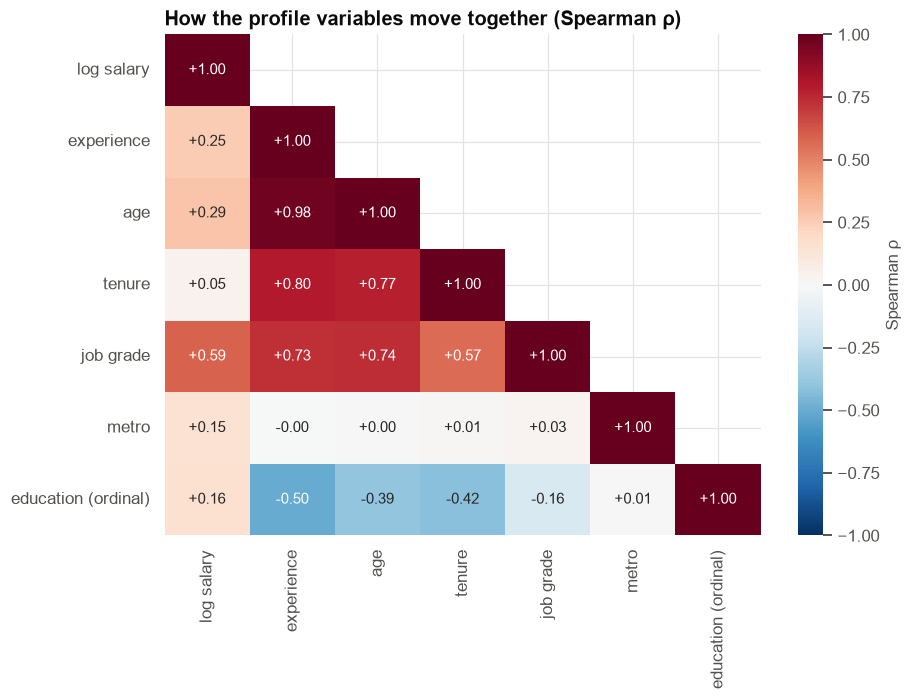

In [4]:
corr_cols = {"log_salary": "log salary", "years_experience": "experience", "age": "age",
             "years_at_current_employer": "tenure", "job_grade": "job grade", "metro_city": "metro"}
tmp = cust[list(corr_cols)].rename(columns=corr_cols)
tmp["education (ordinal)"] = cust["education"].astype(str).map({e: i for i, e in enumerate(EDU_ORDER)})
corr = tmp.corr(method="spearman")
save_table(corr, "spearman_correlations", PATHS["tables"])

fig, ax = plt.subplots(figsize=(8.5, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt="+.2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax,
            cbar_kws={"label": "Spearman ρ"}, annot_kws={"size": 10})
ax.set_title("How the profile variables move together (Spearman ρ)", loc="left")
fig.tight_layout()
save_fig(fig, "fig01_correlation_matrix", PATHS["figures"])
plt.show()

**Observation.** Salary correlates most with **job grade** (≈ 0.6), modestly with experience (≈ 0.25) and age, weakly
with education (≈ 0.16) and barely at all with **tenure** (≈ 0.05). Experience is strongly tied to job grade (≈ 0.73)
and tenure (≈ 0.8), and **negatively** to education (≈ −0.5). Age and experience are almost the same variable (≈ 0.98).

**Interpretation.** The predictors are tangled. A variable's *individual* correlation with salary mixes its own
contribution with those of everything it travels with. That is exactly why the dashboard and the two model versions
disagree.

**Decision.** Because age and experience carry almost the same information (ρ ≈ 0.98), we use **experience**, the
variable on the application form, and leave age out. Having both would inflate standard errors without adding
information (Case 09).

## Section 6 — Visualisation: the four puzzles the team brought us

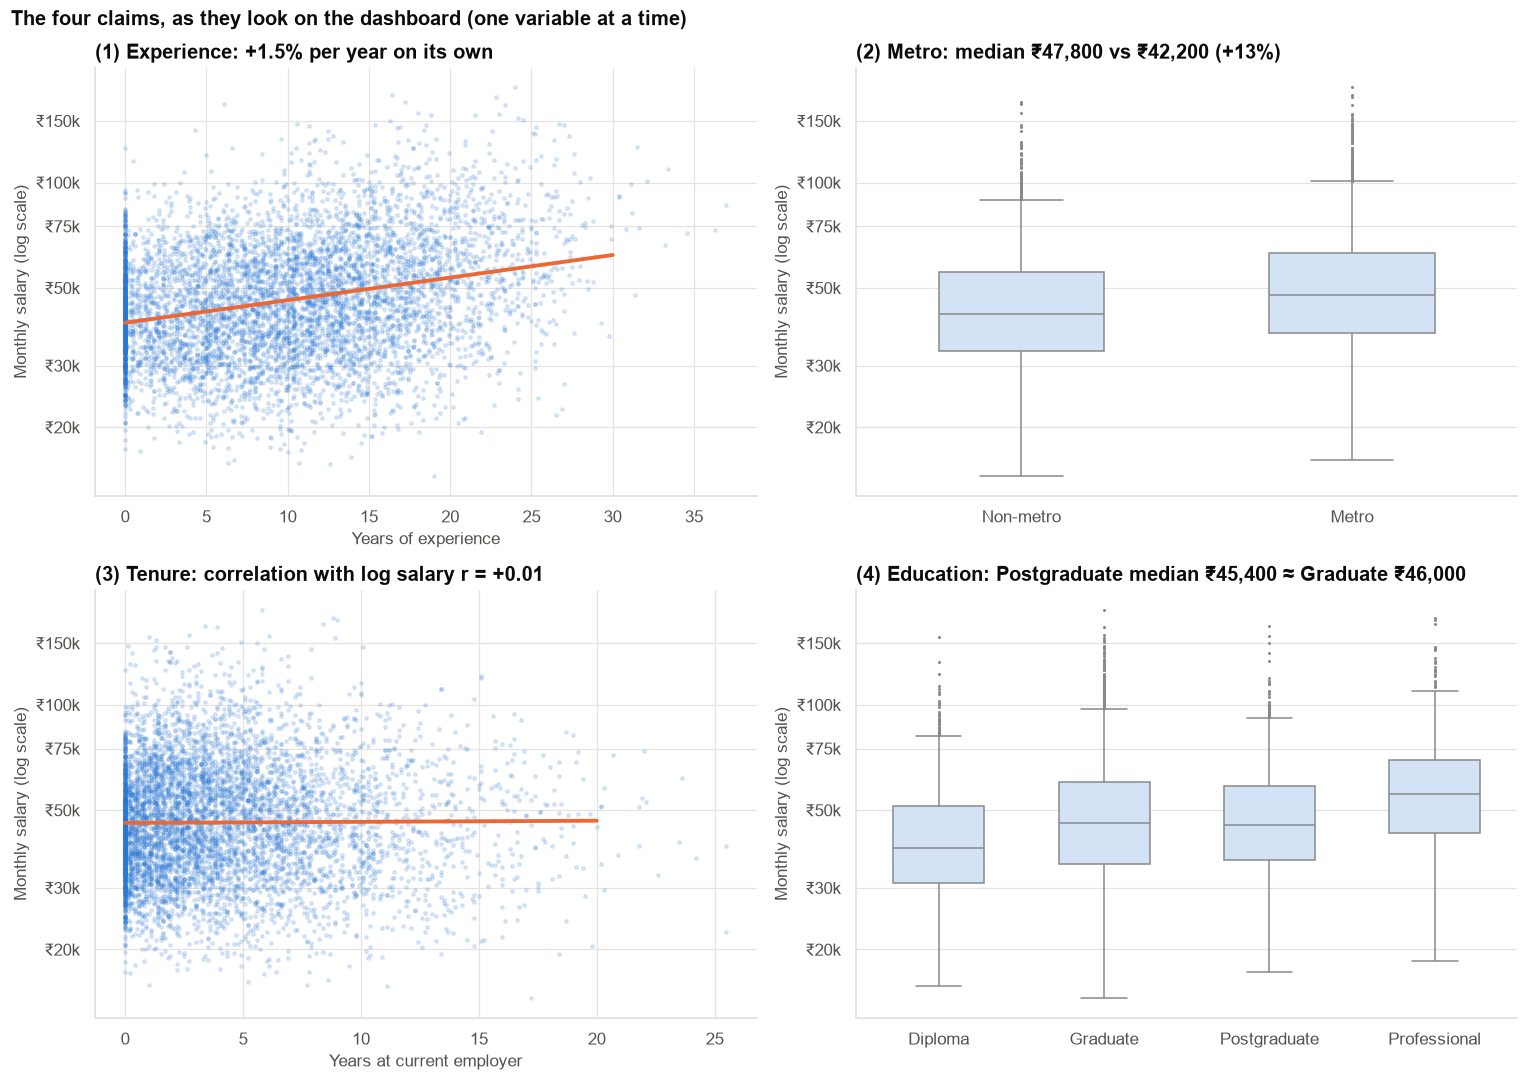

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax = axes[0, 0]
ax.scatter(cust["years_experience"], cust["monthly_salary"], s=5, alpha=0.15, color=PRIMARY)
b = np.polyfit(cust["years_experience"], cust["log_salary"], 1)
xs = np.linspace(0, 30, 50)
ax.plot(xs, np.exp(np.polyval(b, xs)), color=HIGHLIGHT, lw=2.5)
log_salary_axis(ax)
ax.set(title=f"(1) Experience: +{pct(b[0]):.1f}% per year on its own", xlabel="Years of experience", ylabel="Monthly salary (log scale)")

ax = axes[0, 1]
med = cust.groupby("metro_city")["monthly_salary"].median()
sns.boxplot(data=cust, x="metro_city", y="monthly_salary", ax=ax, color="#cde2fb", fliersize=1, width=0.5)
log_salary_axis(ax)
ax.set_xticks([0, 1], ["Non-metro", "Metro"])
ax.set(title=f"(2) Metro: median {fmt_money(med[1])} vs {fmt_money(med[0])} (+{100 * (med[1] / med[0] - 1):.0f}%)",
       xlabel="", ylabel="Monthly salary (log scale)")

ax = axes[1, 0]
ax.scatter(cust["years_at_current_employer"], cust["monthly_salary"], s=5, alpha=0.15, color=PRIMARY)
r_ten = stats.pearsonr(cust["years_at_current_employer"], cust["log_salary"])[0]
b = np.polyfit(cust["years_at_current_employer"], cust["log_salary"], 1)
xs = np.linspace(0, 20, 50)
ax.plot(xs, np.exp(np.polyval(b, xs)), color=HIGHLIGHT, lw=2.5)
log_salary_axis(ax)
ax.set(title=f"(3) Tenure: correlation with log salary r = {r_ten:+.2f}", xlabel="Years at current employer",
       ylabel="Monthly salary (log scale)")

ax = axes[1, 1]
sns.boxplot(data=cust, x="education", y="monthly_salary", order=EDU_ORDER, ax=ax, color="#cde2fb", fliersize=1, width=0.55)
log_salary_axis(ax)
med_e = cust.groupby("education", observed=True)["monthly_salary"].median()
ax.set(title=f"(4) Education: Postgraduate median {fmt_money(med_e['Postgraduate'])} ≈ Graduate {fmt_money(med_e['Graduate'])}",
       xlabel="", ylabel="Monthly salary (log scale)")
fig.suptitle("The four claims, as they look on the dashboard (one variable at a time)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig02_four_puzzles", PATHS["figures"])
plt.show()

**Observation.** On the dashboard: experience has a positive slope; metro customers earn more; tenure shows nothing;
postgraduates earn the same as graduates.

**Interpretation.** Every one of these is a **marginal** (one-variable) view. The rest of the case shows that **all
four** are misleading, in four *different* ways.

**Caveat.** These plots are not wrong. They correctly describe the customer base. They are wrong only when read as
"what happens to salary if *this one thing* differs and nothing else does".

## Section 7 — Method selection: four ways a coefficient can change

When we add a variable Z to a regression of Y on X, the coefficient of X can change for different reasons. Each one
has a different structure (a **causal diagram**, or DAG: arrows mean "causes"):

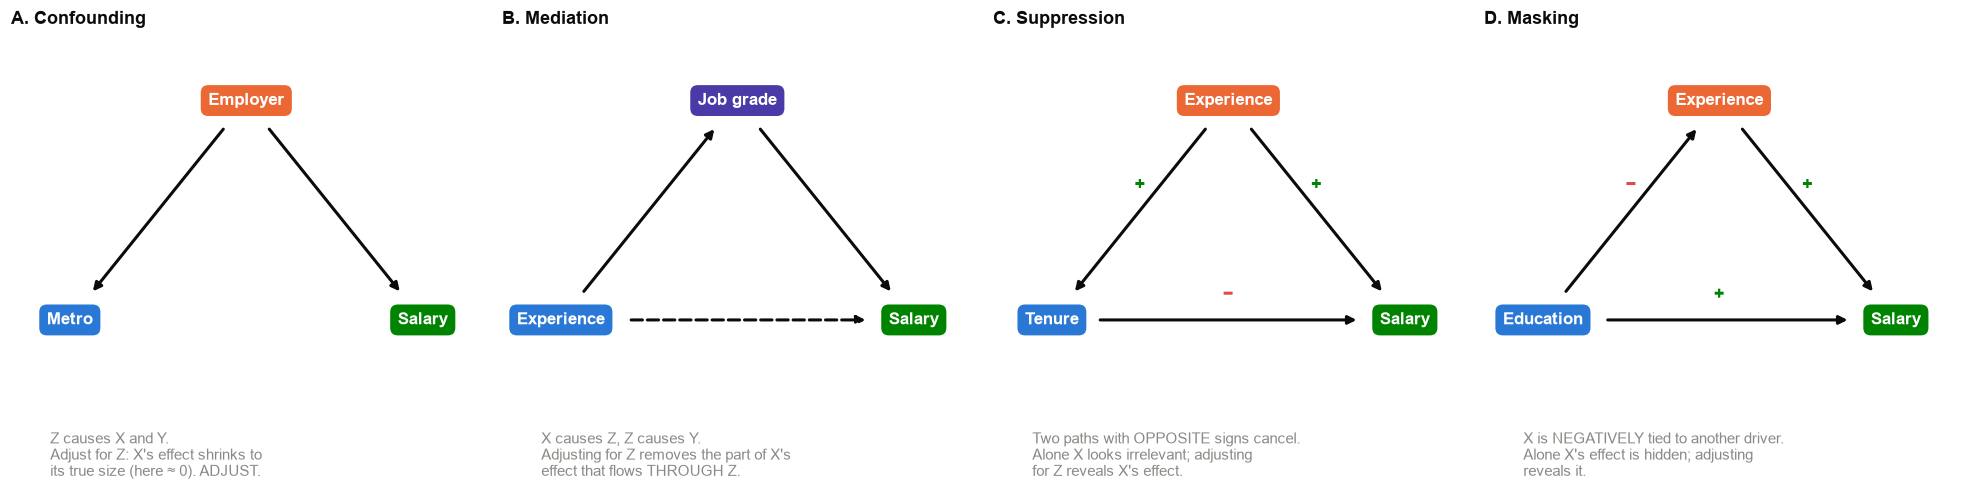

In [6]:
def draw_dag(ax, nodes, edges, title, subtitle, dashed=()):
    for name, (x, y, col) in nodes.items():
        ax.text(x, y, name, ha="center", va="center", fontsize=11, fontweight="bold", color="white",
                bbox=dict(boxstyle="round,pad=0.45", fc=col, ec="none"))
    for (a, b_, sign) in edges:
        (x1, y1, _), (x2, y2, _) = nodes[a], nodes[b_]
        sa, sb = (3.6 * len(a) + 10, 3.6 * len(b_) + 10) if y1 == y2 else (24, 24)
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="-|>", lw=2, color=INK, shrinkA=sa, shrinkB=sb,
                                    linestyle="--" if (a, b_) in dashed else "-"))
        if sign:
            ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.06, sign, ha="center", fontsize=12, color=COLORS["red"] if sign == "−" else COLORS["green"],
                    fontweight="bold")
    ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.15, 1.05); ax.axis("off")
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.text(0.0, -0.13, subtitle, fontsize=9.5, color=INK_MUTED, va="top", wrap=True)

X, Y, Z, M = PRIMARY, COLORS["green"], HIGHLIGHT, COLORS["violet"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
draw_dag(axes[0], {"Employer": (0.5, 0.85, Z), "Metro": (0.05, 0.2, X), "Salary": (0.95, 0.2, Y)},
         [("Employer", "Metro", ""), ("Employer", "Salary", "")],
         "A. Confounding", "Z causes X and Y.\nAdjust for Z: X's effect shrinks to\nits true size (here ≈ 0). ADJUST.")
draw_dag(axes[1], {"Experience": (0.05, 0.2, X), "Job grade": (0.5, 0.85, M), "Salary": (0.95, 0.2, Y)},
         [("Experience", "Job grade", ""), ("Job grade", "Salary", ""), ("Experience", "Salary", "")],
         "B. Mediation", "X causes Z, Z causes Y.\nAdjusting for Z removes the part of X's\neffect that flows THROUGH Z.", dashed=(("Experience", "Salary"),))
draw_dag(axes[2], {"Experience": (0.5, 0.85, Z), "Tenure": (0.05, 0.2, X), "Salary": (0.95, 0.2, Y)},
         [("Experience", "Tenure", "+"), ("Experience", "Salary", "+"), ("Tenure", "Salary", "−")],
         "C. Suppression", "Two paths with OPPOSITE signs cancel.\nAlone X looks irrelevant; adjusting\nfor Z reveals X's effect.")
draw_dag(axes[3], {"Experience": (0.5, 0.85, Z), "Education": (0.05, 0.2, X), "Salary": (0.95, 0.2, Y)},
         [("Education", "Experience", "−"), ("Experience", "Salary", "+"), ("Education", "Salary", "+")],
         "D. Masking", "X is NEGATIVELY tied to another driver.\nAlone X's effect is hidden; adjusting\nreveals it.")
fig.tight_layout()
save_fig(fig, "fig03_causal_structures", PATHS["figures"])
plt.show()

**The key point.** Confounding and mediation look **identical in the data**: in both, X's coefficient shrinks when Z
is added. The data alone cannot tell them apart. You need **outside knowledge**, above all **time order**:
- If Z happens **before** X (employer type was decided before the customer moved city), Z can be a **confounder**:
  adjust for it.
- If Z happens **after** X and because of it (grade is reached *through* years of experience), Z is a **mediator**:
  adjusting for it answers a *different* question ("what is X's effect apart from its effect through Z?").

**The model.** One linear regression on log(salary), with variables added in steps so we can watch coefficients
move:

  log(salary) = β₀ + β₁·experience + education dummies + employer dummies + β·metro + β·tenure + grade dummies + ε

| Candidate | Verdict |
|---|---|
| Correlations, one variable at a time | ❌ That is what produced the four puzzles |
| **Nested multiple regressions + decomposition** | ✅ Shows *how* and *why* each coefficient moves |
| Regression with every variable, read once | ⚠️ Gives conditional effects but hides the story, and invites adjusting for mediators by accident |
| Tree-based ML | ❌ Not needed; the question is about the meaning of effects, not prediction accuracy (Case 13) |

## Section 8 — Puzzle 1: why did experience "stop mattering"?

### 8.1 The coefficient path

In [7]:
steps = {
    "M0: experience only": "log_salary ~ years_experience",
    "M1: + education": "log_salary ~ years_experience + education",
    "M2: + employer": "log_salary ~ years_experience + education + employer_category",
    "M3: + metro": "log_salary ~ years_experience + education + employer_category + metro_city",
    "M4: + tenure  (= model v1)": "log_salary ~ years_experience + education + employer_category + metro_city + years_at_current_employer",
    "M5: + job grade  (= model v2)": "log_salary ~ years_experience + education + employer_category + metro_city + years_at_current_employer + grade",
}
models = {k: smf.ols(f, cust).fit() for k, f in steps.items()}
track = {"years_experience": "experience (%/yr)", "years_at_current_employer": "tenure (%/yr)", "metro_city": "metro (%)",
         "education[T.Postgraduate]": "Postgraduate vs Graduate (%)"}
path = pd.DataFrame({k: {lab: pct(m.params[t]) if t in m.params else np.nan for t, lab in track.items()}
                     for k, m in models.items()}).T
path["experience SE (pp)"] = [100 * m.bse["years_experience"] for m in models.values()]
path["R²"] = [m.rsquared for m in models.values()]
save_table(path, "coefficient_path", PATHS["tables"])
path

,experience (%/yr),tenure (%/yr),metro (%),Postgraduate vs Graduate (%),experience SE (pp),R²
M0: experience only,1.4950,NaN,NaN,NaN,0.0669,0.0759
M1: + education,2.4965,NaN,NaN,20.6102,0.0740,0.1914
M2: + employer,2.5376,NaN,NaN,20.5312,0.0660,0.3591
M3: + metro,2.5388,NaN,-1.6062,20.5266,0.0660,0.3595
M4: + tenure (= model v1),4.2843,-3.9265,-0.9602,20.7523,0.0835,0.4425
M5: + job grade (= model v2),0.5286,-3.9732,-0.9348,8.6173,0.0851,0.6745


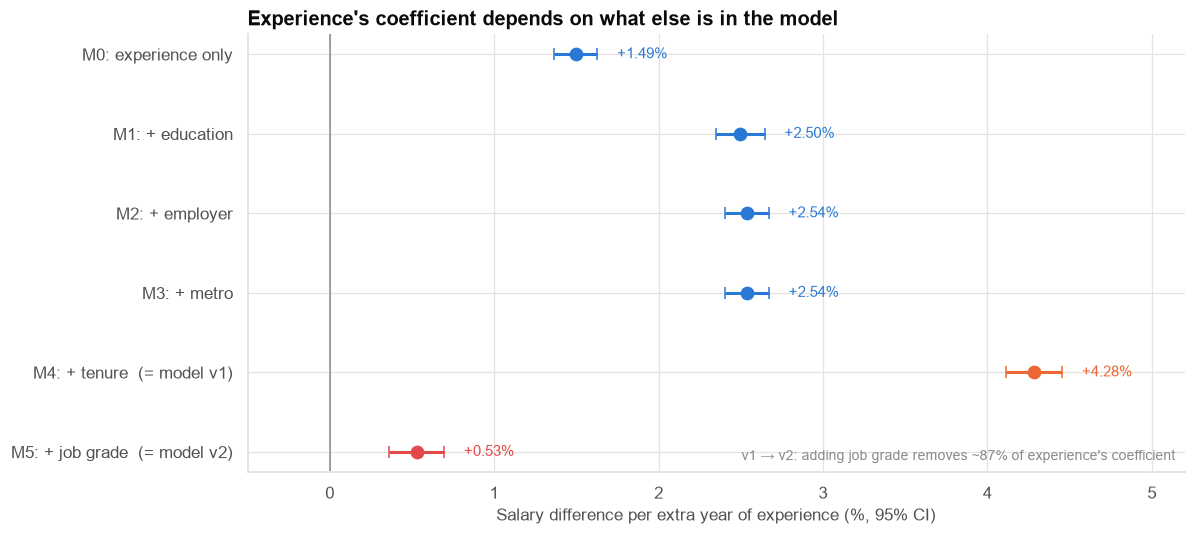

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
labels = list(models)
est = [coef_row(m, "years_experience") for m in models.values()]
y = np.arange(len(labels))[::-1]
for yi, e, lab in zip(y, est, labels):
    col = COLORS["red"] if "grade" in lab else (HIGHLIGHT if "tenure" in lab else PRIMARY)
    ax.errorbar(e["% effect"], yi, xerr=[[e["% effect"] - e["ci_low %"]], [e["ci_high %"] - e["% effect"]]],
                fmt="o", color=col, ms=8, capsize=4, lw=2)
    ax.text(e["ci_high %"] + 0.12, yi, f"{e['% effect']:+.2f}%", va="center", fontsize=10, color=col)
ax.axvline(0, color=INK_MUTED, lw=1)
ax.set_yticks(y, labels)
ax.set(xlabel="Salary difference per extra year of experience (%, 95% CI)", xlim=(-0.5, 5.2),
       title="Experience's coefficient depends on what else is in the model")
add_note(ax, "v1 → v2: adding job grade removes ~87% of experience's coefficient", "lower right")
fig.tight_layout()
save_fig(fig, "fig04_experience_coefficient_path", PATHS["figures"])
plt.show()

**Observation.** Experience's coefficient changes at almost every step:
- **+1.5%/yr alone (M0)**, rising to **+2.5%** once education is added (M1), and to **+4.3%** once tenure is added
  (M4, model v1);
- then dropping to **≈ +0.5%** when job grade is added (M5, model v2).
- Its confidence intervals are narrow throughout. Each estimate is precise; they are estimates of **different
  quantities**.

**Interpretation.** Each model asks a different question:
- M0: how do customers with more experience differ, *full stop*?
- M4: how do customers differ per extra year of experience, at the **same education, employer, city and tenure**?
- M5: …at the same everything **and the same job grade**?

The rises from M0 to M4 come from **masking** (education) and **suppression** (tenure), Puzzles 3 and 4. The fall
from M4 to M5 is Puzzle 1.

### 8.2 The picture: experience works through job grade

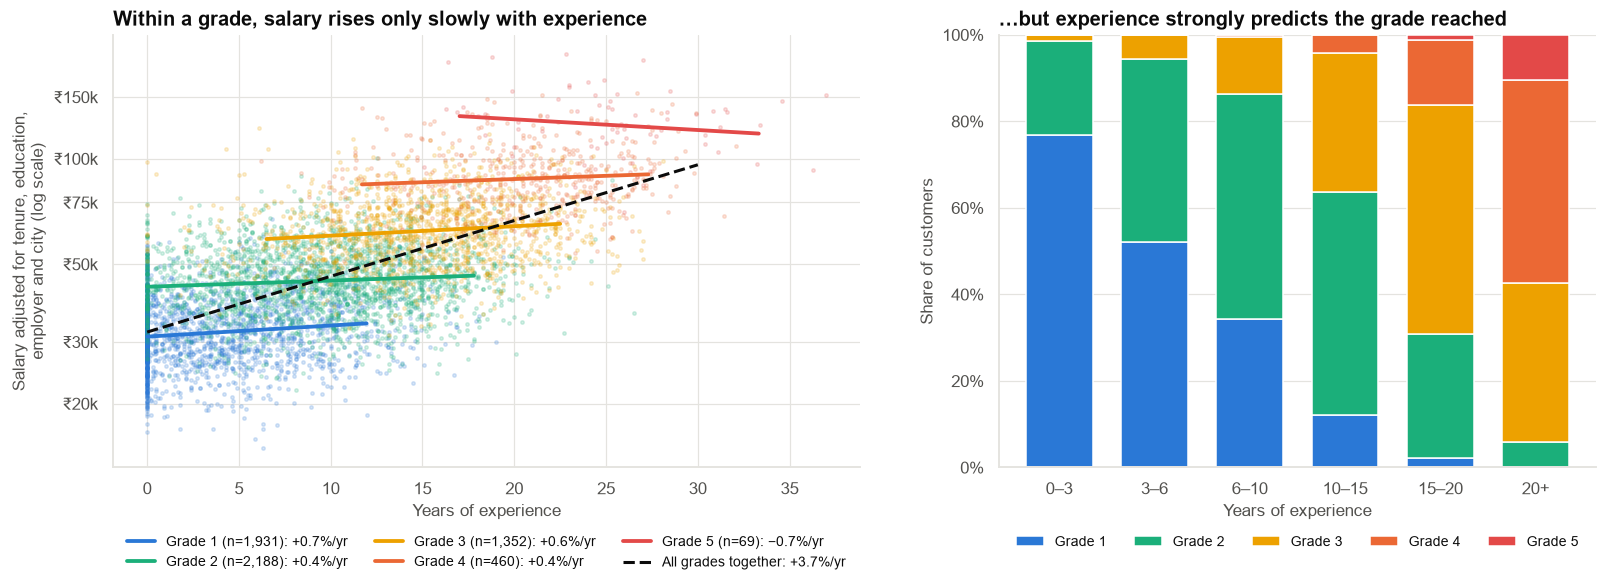

In [9]:
# Remove the model-v2 contributions of tenure, education, employer and city, so every customer is shown
# "as if" they had the average tenure, education mix, employer mix and city mix (a partial-residual view).
pv2 = models["M5: + job grade  (= model v2)"].params
other = pd.Series(0.0, index=cust.index)
for term, val in pv2.items():
    if term in ("years_at_current_employer", "metro_city"):
        x = cust[term]
    elif term.startswith("education[T.") or term.startswith("employer_category[T."):
        var, lvl = term.split("[T.")
        x = (cust[var] == lvl.rstrip("]")).astype(float)
    else:
        continue
    other += val * (x - x.mean())
cust["adj_log_salary"] = cust["log_salary"] - other

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
gcols = [COLORS["blue"], COLORS["aqua"], COLORS["yellow"], HIGHLIGHT, COLORS["red"]]
for g, col in zip(range(1, 6), gcols):
    sub = cust[cust["job_grade"] == g]
    ax.scatter(sub["years_experience"], np.exp(sub["adj_log_salary"]), s=5, alpha=0.18, color=col)
    lo, hi = sub["years_experience"].quantile([0.05, 0.95])
    bg = np.polyfit(sub["years_experience"], sub["adj_log_salary"], 1)
    xs = np.linspace(lo, hi, 20)
    ax.plot(xs, np.exp(np.polyval(bg, xs)), color=col, lw=2.5,
            label=f"Grade {g} (n={len(sub):,}): {pct(bg[0]):+.1f}%/yr".replace("-", "−"))
b0 = np.polyfit(cust["years_experience"], cust["adj_log_salary"], 1)
xs = np.linspace(0, 30, 50)
ax.plot(xs, np.exp(np.polyval(b0, xs)), color=INK, lw=2, ls="--", label=f"All grades together: {pct(b0[0]):+.1f}%/yr")
log_salary_axis(ax)
ax.set(xlabel="Years of experience", ylabel="Salary adjusted for tenure, education,\nemployer and city (log scale)",
       title="Within a grade, salary rises only slowly with experience")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=9, frameon=False)

ax = axes[1]
grade_by_exp = (cust.assign(band=pd.cut(cust["years_experience"], [-0.1, 3, 6, 10, 15, 20, 40],
                                        labels=["0–3", "3–6", "6–10", "10–15", "15–20", "20+"]))
                .groupby("band", observed=True)["job_grade"].value_counts(normalize=True).unstack().fillna(0))
bottom = np.zeros(len(grade_by_exp))
for g, col in zip(range(1, 6), gcols):
    ax.bar(grade_by_exp.index.astype(str), grade_by_exp[g], bottom=bottom, color=col, label=f"Grade {g}", width=0.7)
    bottom += grade_by_exp[g].to_numpy()
ax.set(xlabel="Years of experience", ylabel="Share of customers", title="…but experience strongly predicts the grade reached")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=5, fontsize=9, frameon=False)
fig.tight_layout()
save_fig(fig, "fig05_experience_through_grade", PATHS["figures"])
plt.show()

**Observation.** After adjusting for tenure, education, employer and city, salary within each grade rises with
experience by only about 0–1% a year (left; slopes are noisy in the small top grades), while across all grades
together it rises about 4% a year. Across the customer base, experience strongly predicts grade: almost nobody with under 3 years
is above grade 2, and most of those with 15+ years are at grade 3 or above (right).

**Why the adjustment?** Without it, the raw within-grade slopes are even **negative**: at the same grade, more
experienced customers have longer tenure (fewer job switches), which lowers pay (Puzzle 3). One omitted variable can
hide inside another analysis; the left panel removes it.

**Interpretation.** Experience raises salary **mainly by getting people promoted**. Once you compare customers *at the
same grade*, little is left for experience to explain. That is **mediation**: grade sits *on the path* from experience
to salary.

### 8.3 The omitted-variable-bias formula, checked exactly

For linear regression there is an exact identity. If the "short" model leaves out Z and the "long" model includes it:

  **β_short = β_long + γ · δ**

- γ = Z's coefficient in the long model (how Z relates to Y, holding X fixed);
- δ = the coefficient of X when Z is regressed on X and the other controls (how Z moves with X).

With several added variables (here 4 grade dummies), the change is the **sum** of γ·δ over them. This is the
**Gelbach decomposition**: it splits a coefficient's change exactly between the variables added.

In [10]:
controls = "years_experience + education + employer_category + metro_city + years_at_current_employer"
m_v1, m_v2 = models["M4: + tenure  (= model v1)"], models["M5: + job grade  (= model v2)"]
rows = []
for g in [2, 3, 4, 5]:
    term = f"grade[T.{g}]"
    aux = smf.ols(f"I((job_grade == {g}) * 1.0) ~ {controls}", cust).fit()
    gamma, delta = m_v2.params[term], aux.params["years_experience"]
    rows.append({"added variable": f"grade {g} (vs 1)", "γ: effect on log salary": gamma,
                 "δ: change per year of experience": delta, "γ × δ": gamma * delta})
ovb = pd.DataFrame(rows).set_index("added variable")
ovb.loc["TOTAL"] = [np.nan, np.nan, ovb["γ × δ"].sum()]
b_short, b_long = m_v1.params["years_experience"], m_v2.params["years_experience"]
save_table(ovb, "ovb_decomposition_grade", PATHS["tables"])
display(ovb)
print(f"β_short (v1) = {b_short:.5f}   β_long (v2) = {b_long:.5f}   difference = {b_short - b_long:.5f}")
print(f"Sum of γ·δ over the grade dummies             = {ovb.loc['TOTAL', 'γ × δ']:.5f}   (identical: the formula is exact)")
print(f"Share of v1's experience coefficient explained by grade: {(b_short - b_long) / b_short:.0%}")

,γ: effect on log salary,δ: change per year of experience,γ × δ
added variable,,,
grade 2 (vs 1),0.3085,-0.0038,-0.0012
grade 3 (vs 1),0.6076,0.0258,0.0157
grade 4 (vs 1),0.9219,0.0185,0.0171
grade 5 (vs 1),1.2506,0.0041,0.0051
TOTAL,NaN,NaN,0.0367


β_short (v1) = 0.04195   β_long (v2) = 0.00527   difference = 0.03668
Sum of γ·δ over the grade dummies             = 0.03668   (identical: the formula is exact)
Share of v1's experience coefficient explained by grade: 87%


**Observation.** The four γ·δ terms add up **exactly** to the drop in experience's coefficient. About 87% of v1's
experience coefficient is accounted for by grade.

**Interpretation.** Each extra year of experience raises the chance of being in a higher grade (δ > 0), and higher
grades pay much more (γ > 0). In v1 (no grade), experience's coefficient picks up this whole chain. In v2, the grade
dummies take it over.

**The general rule for predicting the direction of omitted-variable bias:**

| Z's effect on Y (γ) | Z's relation with X (δ) | Leaving Z out makes X's coefficient… |
|---|---|---|
| + | + | too **large** (biased up) |
| + | − | too **small** (biased down, can hide or flip X's effect) |
| − | + | too **small** |
| − | − | too **large** |
| 0 | any | unbiased (Z is irrelevant to Y) |
| any | 0 | unbiased (Z is unrelated to X; adding Z only improves precision) |

### 8.4 Confounder or mediator? Total, direct and indirect effects

In [11]:
def effects(df):
    tot = smf.ols(steps["M4: + tenure  (= model v1)"], df).fit().params["years_experience"]
    dire = smf.ols(steps["M5: + job grade  (= model v2)"], df).fit().params["years_experience"]
    return tot, dire, tot - dire

tot, dire, ind = effects(cust)
boot = []
for _ in range(500):
    s = cust.iloc[rng.integers(0, len(cust), len(cust))]
    boot.append(effects(s))
boot = np.array(boot)
share = boot[:, 2] / boot[:, 0]
med_tbl = pd.DataFrame({
    "estimate (%/yr)": [pct(tot), pct(dire), 100 * ind, np.nan],
    "95% CI low": [pct(np.percentile(boot[:, 0], 2.5)), pct(np.percentile(boot[:, 1], 2.5)), 100 * np.percentile(boot[:, 2], 2.5),
                   100 * np.percentile(share, 2.5)],
    "95% CI high": [pct(np.percentile(boot[:, 0], 97.5)), pct(np.percentile(boot[:, 1], 97.5)), 100 * np.percentile(boot[:, 2], 97.5),
                    100 * np.percentile(share, 97.5)],
    "share (%)": [100.0, 100 * dire / tot, 100 * ind / tot, 100 * ind / tot],
}, index=["TOTAL effect (v1: grade not held fixed)", "DIRECT effect (v2: same grade)",
          "INDIRECT effect via grade (log points ×100)", "share of total that runs through grade"])
save_table(med_tbl, "mediation_experience_grade", PATHS["tables"])
med_tbl

,estimate (%/yr),95% CI low,95% CI high,share (%)
TOTAL effect (v1: grade not held fixed),4.2843,4.1182,4.4518,100.0000
DIRECT effect (v2: same grade),0.5286,0.3548,0.7027,12.5684
INDIRECT effect via grade (log points ×100),3.6678,3.5128,3.8247,87.4316
share of total that runs through grade,NaN,83.9134,91.3399,87.4316


**Observation.** Of experience's **total** association with salary (≈ +4.3% per year, holding education, employer,
city and tenure fixed), about **87%** (95% bootstrap CI 84%–91%) runs **through job grade**. The **direct** part,
at the same grade, is about +0.5% per year: small, but precisely estimated and not zero.

**Interpretation: confounder or mediator?** Time order settles it. Customers accumulate experience *first* and are
promoted *as a result*. Grade cannot cause experience. So grade is a **mediator**, not a confounder. Experience did
not "stop mattering": its effect now **shows up in the grade variable**.

**What each number is good for:**

| Question | Right model | Answer |
|---|---|---|
| *"Two customers differ by 5 years of experience; we know nothing else about grade. How different are their salaries?"* | v1 (total effect) | ≈ +23% |
| *"Two customers are at the same grade; one has 5 more years. How different are their salaries?"* | v2 (direct effect) | ≈ +3% |
| *"Should experience stay on the application form?"* | Prediction comparison (Section 13) | Yes, for the 40% of customers without a verified grade |

**Caveats.**
- The total/direct/indirect split is a description of **associations** in a linear model. Reading it causally needs
  the strong assumption that nothing unmeasured (e.g. individual ability) drives both promotions and pay.
- The "indirect = total − direct" arithmetic is exact only for linear models like this one.

> **Rule.** Do not adjust for a **mediator** when you want the **total effect** of a variable. Do adjust for it when
> you want the **direct effect**, or when the goal is pure **prediction** and the mediator is available at
> prediction time.

## Section 9 — Puzzle 2: is the metro uplift real? (confounding)

In [12]:
m_metro0 = smf.ols("log_salary ~ metro_city", cust).fit()
m_metro1 = smf.ols("log_salary ~ metro_city + employer_category", cust).fit()
m_metroF = m_v2
metro_tbl = pd.DataFrame({"metro alone": coef_row(m_metro0, "metro_city"),
                          "+ employer type": coef_row(m_metro1, "metro_city"),
                          "full model v2": coef_row(m_metroF, "metro_city")}).T
save_table(metro_tbl, "metro_effect", PATHS["tables"])
display(metro_tbl)

strat = []
for e, sub in cust.groupby("employer_category", observed=True):
    a, b_ = sub.loc[sub.metro_city == 1, "log_salary"], sub.loc[sub.metro_city == 0, "log_salary"]
    t = stats.ttest_ind(a, b_, equal_var=False)
    ci = t.confidence_interval()
    strat.append({"employer": e, "share in metro": sub["metro_city"].mean(),
                  "median salary": sub["monthly_salary"].median(), "n": len(sub),
                  "metro − non-metro (%)": pct(a.mean() - b_.mean()), "ci_low %": pct(ci.low), "ci_high %": pct(ci.high),
                  "p_value": t.pvalue})
strat = pd.DataFrame(strat).set_index("employer")
save_table(strat, "metro_within_employer", PATHS["tables"])
strat

,coef,% effect,ci_low %,ci_high %,std_err,p_value
metro alone,0.1150,12.1832,10.0369,14.3714,0.0099,0.0000
+ employer type,-0.0106,-1.0524,-2.9937,0.9277,0.0101,0.2953
full model v2,-0.0094,-0.9348,-2.1525,0.2980,0.0063,0.1366


,share in metro,median salary,n,metro − non-metro (%),ci_low %,ci_high %,p_value
employer,,,,,,,
Large Indian corporate,0.5434,"45,300.0000",1660,-0.4026,-3.8490,3.1674,0.8223
MNC,0.8451,"57,300.0000",1317,-0.6674,-5.9439,4.9050,0.8093
Government-PSU,0.3601,"42,500.0000",922,-6.3637,-10.6265,-1.8976,0.0057
SME,0.3509,"36,700.0000",1502,0.9898,-2.6327,4.7470,0.5969
Startup,0.8815,"50,000.0000",599,1.1333,-7.0137,9.9941,0.7904


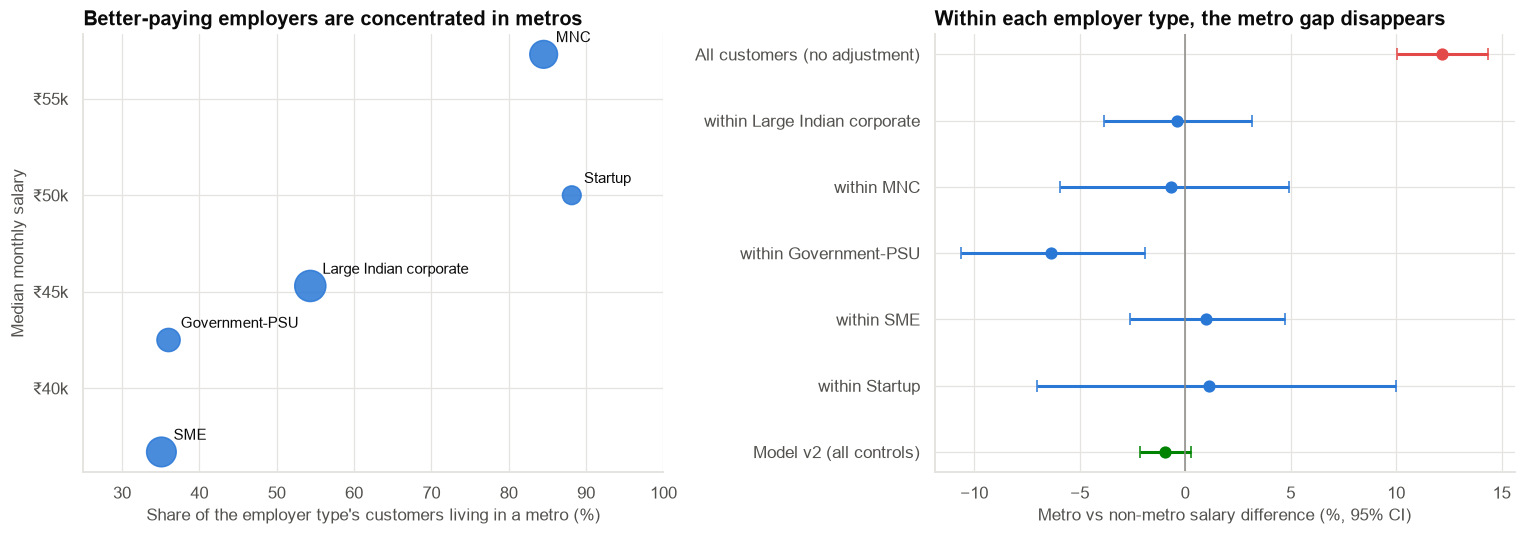

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
sc = ax.scatter(strat["share in metro"] * 100, strat["median salary"], s=strat["n"] / 4, color=PRIMARY, alpha=0.85)
for e, r in strat.iterrows():
    ax.annotate(e, (r["share in metro"] * 100, r["median salary"]), xytext=(8, 8), textcoords="offset points", fontsize=10)
ax.yaxis.set_major_formatter(kfmt)
ax.set(xlabel="Share of the employer type's customers living in a metro (%)", ylabel="Median monthly salary",
       title="Better-paying employers are concentrated in metros", xlim=(25, 100))
ax = axes[1]
items = [("All customers (no adjustment)", metro_tbl.loc["metro alone"])] + \
        [(f"within {e}", r) for e, r in strat.iterrows()] + [("Model v2 (all controls)", metro_tbl.loc["full model v2"])]
for i, (lab, r) in enumerate(items[::-1]):
    est = r["% effect"] if "% effect" in r else r["metro − non-metro (%)"]
    col = COLORS["red"] if lab.startswith("All") else (COLORS["green"] if lab.startswith("Model") else PRIMARY)
    ax.errorbar(est, i, xerr=[[est - r["ci_low %"]], [r["ci_high %"] - est]], fmt="o", color=col, capsize=4, ms=7, lw=2)
ax.set_yticks(range(len(items)), [l for l, _ in items[::-1]])
ax.axvline(0, color=INK_MUTED, lw=1)
ax.set(xlabel="Metro vs non-metro salary difference (%, 95% CI)", title="Within each employer type, the metro gap disappears")
fig.tight_layout()
save_fig(fig, "fig06_metro_confounding", PATHS["figures"])
plt.show()

**Observation.** Metro customers earn about **12% more** overall. But MNCs and startups (the best payers) have 85–90% of
their customers in metros, against about 35% for government/PSU and SME employers. Within each employer type, the metro
gap is close to zero; in the full model it is about **−1%**, with a CI that includes zero.

**Interpretation.** Employer type is a **common cause** of living in a metro and of salary. It is a **confounder**:
the metro "uplift" is an employer-type effect in disguise. Employer type was decided *before*, and partly *because
of*, where people live and work, so adjusting for it is correct.

**Caveat (one subgroup differs).** One of the five within-employer gaps is significant: government/PSU metro customers
earn about 6% **less** (p ≈ 0.006, still below the Bonferroni threshold of 0.05 / 5 = 0.01; Case 19). It is either a
chance result among the five comparisons or a real PSU pattern (for example, metro postings for junior staff). Either
way it points **against** an uplift, not for one. The pooled, adjusted estimate is the one to use, with a follow-up
check on PSU customers.

**Business implication.** A metro uplift would **double-count** the employer effect: an MNC employee in a metro would
get both the MNC and the metro uplift. **Reject the proposal.**

## Section 10 — Puzzle 3: tenure has zero correlation. Drop it? (suppression)

In [14]:
m_ten0 = smf.ols("log_salary ~ years_at_current_employer", cust).fit()
m_ten1 = smf.ols("log_salary ~ years_at_current_employer + years_experience", cust).fit()
ten_tbl = pd.DataFrame({"tenure alone": coef_row(m_ten0, "years_at_current_employer"),
                        "+ experience": coef_row(m_ten1, "years_at_current_employer"),
                        "full model v2": coef_row(m_v2, "years_at_current_employer")}).T
ten_tbl["R² of model"] = [m_ten0.rsquared, m_ten1.rsquared, m_v2.rsquared]
save_table(ten_tbl, "tenure_effect", PATHS["tables"])
display(ten_tbl)
m_noten = smf.ols(steps["M5: + job grade  (= model v2)"].replace(" + years_at_current_employer", ""), cust).fit()
f_ten = anova_lm(m_noten, m_v2)
print(f"Experience alone: R² = {models['M0: experience only'].rsquared:.3f};  experience + tenure: R² = {m_ten1.rsquared:.3f}")
print(f"Dropping tenure from v2: F = {f_ten['F'].iloc[1]:.0f}, p = {fmt_p(f_ten['Pr(>F)'].iloc[1])};  "
      f"partial R² = {(m_noten.ssr - m_v2.ssr) / m_noten.ssr:.3f}")

,coef,% effect,ci_low %,ci_high %,std_err,p_value,R² of model
tenure alone,0.0007,0.0743,-0.1638,0.3129,0.0012,0.5411,0.0001
+ experience,-0.0399,-3.9117,-4.2211,-3.6014,0.0016,0.0000,0.1585
full model v2,-0.0405,-3.9732,-4.1660,-3.7800,0.0010,0.0000,0.6745


Experience alone: R² = 0.076;  experience + tenure: R² = 0.158
Dropping tenure from v2: F = 1563, p = < 0.001;  partial R² = 0.207


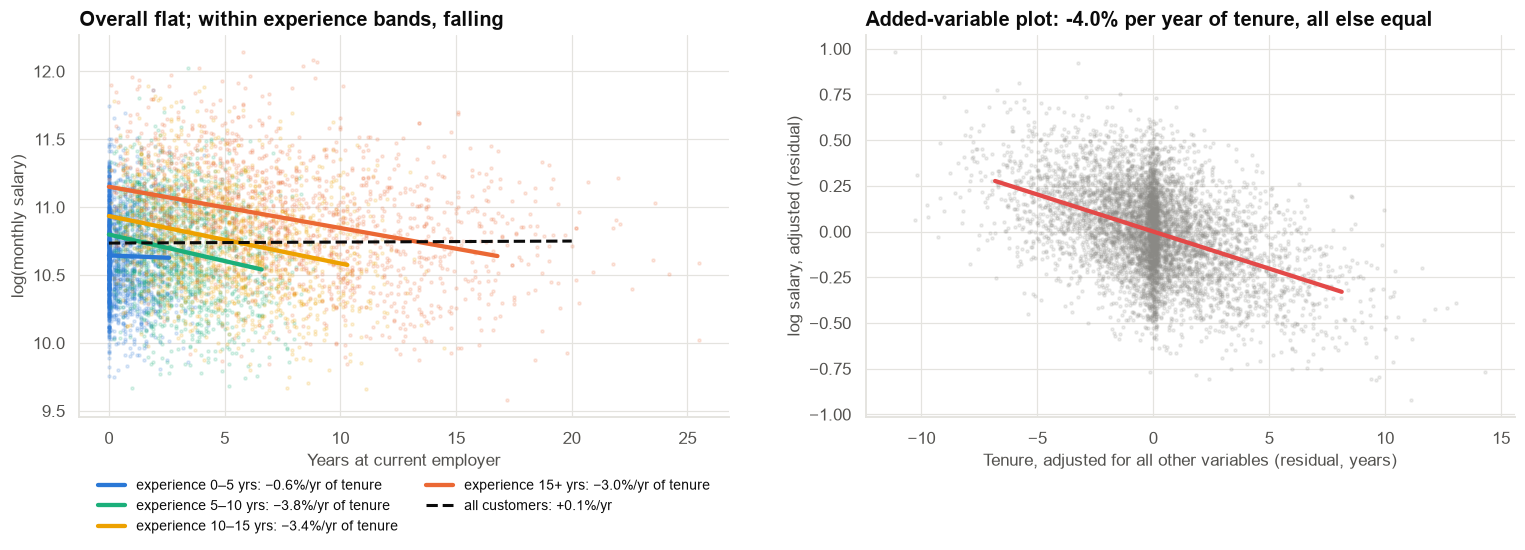

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
bands = pd.cut(cust["years_experience"], [-0.1, 5, 10, 15, 40], labels=["0–5 yrs", "5–10 yrs", "10–15 yrs", "15+ yrs"])
for (lab, sub), col in zip(cust.groupby(bands, observed=True), [COLORS["blue"], COLORS["aqua"], COLORS["yellow"], HIGHLIGHT]):
    ax.scatter(sub["years_at_current_employer"], sub["log_salary"], s=4, alpha=0.15, color=col)
    bb = np.polyfit(sub["years_at_current_employer"], sub["log_salary"], 1)
    xs = np.linspace(0, sub["years_at_current_employer"].quantile(0.95), 20)
    ax.plot(xs, np.polyval(bb, xs), color=col, lw=2.8, label=f"experience {lab}: {pct(bb[0]):+.1f}%/yr of tenure".replace("-", "−"))
b_all = np.polyfit(cust["years_at_current_employer"], cust["log_salary"], 1)
xs = np.linspace(0, 20, 20)
ax.plot(xs, np.polyval(b_all, xs), color=INK, ls="--", lw=2, label=f"all customers: {pct(b_all[0]):+.1f}%/yr")
ax.set(xlabel="Years at current employer", ylabel="log(monthly salary)",
       title="Overall flat; within experience bands, falling")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=9, frameon=False)

others = steps["M5: + job grade  (= model v2)"].split("~")[1].replace(" + years_at_current_employer", "")
ry = smf.ols(f"log_salary ~ {others}", cust).fit().resid
rx = smf.ols(f"years_at_current_employer ~ {others}", cust).fit().resid
ax = axes[1]
ax.scatter(rx, ry, s=4, alpha=0.15, color=INK_MUTED)
bb = np.polyfit(rx, ry, 1)
xs = np.linspace(rx.quantile(0.01), rx.quantile(0.99), 20)
ax.plot(xs, np.polyval(bb, xs), color=COLORS["red"], lw=2.8)
ax.set(xlabel="Tenure, adjusted for all other variables (residual, years)", ylabel="log salary, adjusted (residual)",
       title=f"Added-variable plot: {pct(bb[0]):+.1f}% per year of tenure, all else equal")
fig.tight_layout()
save_fig(fig, "fig07_tenure_suppression", PATHS["figures"])
plt.show()

**Observation.** On its own, tenure has **no** relationship with salary (slope ≈ 0, p ≈ 0.54). Within experience bands,
longer tenure goes with **lower** salary (−3% to −4% per year, except the most junior band, who have little tenure to
vary); with all variables held fixed it is about **−4% per year** of tenure.
Adding tenure to the model raises R² sharply, and dropping it from v2 is overwhelmingly rejected (F-test, partial R²
above).

**Interpretation: suppression.** Tenure sits on two paths with **opposite signs**:
1. More tenure ↔ more experience (ρ ≈ 0.8) ↔ higher salary (**+**);
2. At the same experience, more tenure = fewer job switches = missed switching raises (**−**).

On its own, the two cancel. Holding experience fixed removes path 1 and reveals path 2. Tenure also makes experience's
own coefficient **larger** (Section 8.1: from +2.5% to +4.3%), because tenure "cleans" experience of the
"stayed-put" component that was dragging it down. Each variable **suppresses** irrelevant variation in the other.

**Lesson, worth remembering.**

> **Never drop a variable because its correlation with the target is near zero.** A correlation measures the
> **individual** relationship. A model uses the **conditional** one. Test a variable by what it adds **given the
> others** (nested F-test, partial R², cross-validated error), never by its simple correlation. (Case 13 makes the
> same point with mutual information.)

**Business implication.** **Reject the proposal to drop tenure.** It is one of the most useful variables in the model
(Section 13).

## Section 11 — Puzzle 4: "postgraduates earn the same as graduates" (masking)

In [16]:
m_edu0 = smf.ols("log_salary ~ education", cust).fit()
m_edu1 = smf.ols("log_salary ~ education + years_experience", cust).fit()
rows = {}
for lvl in ["Diploma", "Postgraduate", "Professional"]:
    t = f"education[T.{lvl}]"
    rows[(lvl, "alone")] = coef_row(m_edu0, t)
    rows[(lvl, "same experience")] = coef_row(m_edu1, t)
    rows[(lvl, "model v1")] = coef_row(m_v1, t)
    rows[(lvl, "model v2 (same grade)")] = coef_row(m_v2, t)
edu_tbl = pd.DataFrame(rows).T
save_table(edu_tbl, "education_effect", PATHS["tables"])
display(edu_tbl[["% effect", "ci_low %", "ci_high %", "p_value"]])
display(cust.groupby("education", observed=True).agg(n=("age", "size"), mean_age=("age", "mean"),
                                                     mean_experience=("years_experience", "mean"),
                                                     median_salary=("monthly_salary", "median")).loc[EDU_ORDER])

% effect  ci_low %  ci_high %  p_value
Diploma      alone                  -13.1874  -15.5760   -10.7311   0.0000
             same experience        -14.9643  -17.1186   -12.7539   0.0000
             model v1               -15.0389  -16.8313   -13.2078   0.0000
             model v2 (same grade)   -7.4929   -9.0070    -5.9537   0.0000
Postgraduate alone                   -0.6577   -2.8881     1.6239   0.5689
             same experience         20.6102   17.7757    23.5129   0.0000
             model v1                20.7523   18.3897    23.1620   0.0000
             model v2 (same grade)    8.6173    6.9529    10.3076   0.0000
Professional alone                   20.1121   16.0959    24.2672   0.0000
             same experience         42.7958   38.1796    47.5661   0.0000
             model v1                43.5270   39.6611    47.4999   0.0000
             model v2 (same grade)   17.2550   14.7333    19.8322   0.0000

,n,mean_age,mean_experience,median_salary
education,,,,
Diploma,909,35.5897,13.4608,"39,000.0000"
Graduate,2903,35.2308,12.6221,"46,000.0000"
Postgraduate,1633,28.8083,4.7549,"45,400.0000"
Professional,555,30.2270,5.6067,"55,600.0000"


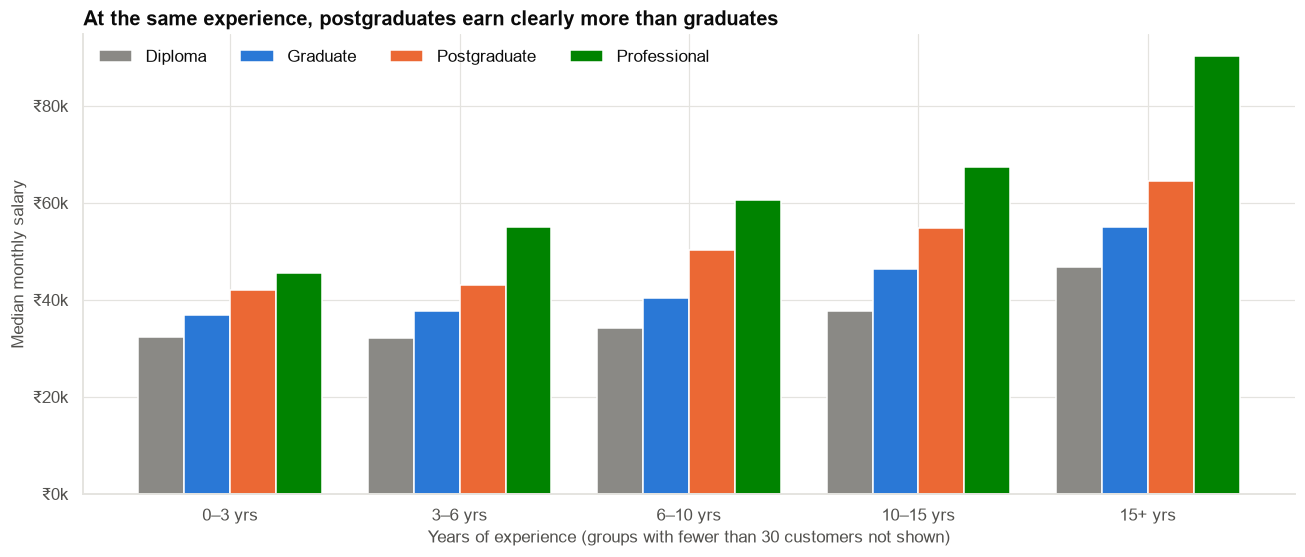

In [17]:
fig, ax = plt.subplots(figsize=(12, 5.2))
bands = pd.cut(cust["years_experience"], [-0.1, 3, 6, 10, 15, 40], labels=["0–3", "3–6", "6–10", "10–15", "15+"])
tbl = (cust.assign(band=bands).groupby(["band", "education"], observed=True)["monthly_salary"]
       .agg(["median", "size"]).reset_index())
tbl = tbl[tbl["size"] >= 30]
width = 0.2
for i, (e, col) in enumerate(zip(EDU_ORDER, [INK_MUTED, PRIMARY, HIGHLIGHT, COLORS["green"]])):
    sub = tbl[tbl["education"] == e]
    xs = sub["band"].cat.codes.to_numpy() + (i - 1.5) * width
    ax.bar(xs, sub["median"], width=width, color=col, label=e)
ax.set_xticks(range(5), ["0–3 yrs", "3–6 yrs", "6–10 yrs", "10–15 yrs", "15+ yrs"])
ax.yaxis.set_major_formatter(kfmt)
ax.set(xlabel="Years of experience (groups with fewer than 30 customers not shown)", ylabel="Median monthly salary",
       title="At the same experience, postgraduates earn clearly more than graduates")
ax.legend(ncol=4, loc="upper left", frameon=False)
fig.tight_layout()
save_fig(fig, "fig08_education_masking", PATHS["figures"])
plt.show()

**Observation.** On its own, the postgraduate–graduate gap is about zero (−0.7%, p ≈ 0.57). At the same experience,
postgraduates earn roughly **21% more** than graduates (table above), and the bars show the gap in every experience
band. The professional-qualification premium also doubles, from +20% alone to about +43%.

**Interpretation: masking.** In our customer base, postgraduates are **much younger** (a campus-hiring partnership
brought many of them in): about 4.8 years of experience on average, against about 12.6 for graduates. Education
raises salary; less experience lowers it. The two cancel in the raw comparison. Experience is a confounder of the
education–salary comparison here, and adjusting for it reveals the education premium. This is **scenario F** of the
README: *a variable looks unimportant because the sample contains a confounder.*

**Note how it shrinks again in v2.** At the same grade, the postgraduate premium falls to about +9%, because part of
education's effect also runs **through** grade (mediation again).

**Business implication.** **Reject the proposal to drop education.** Its premium is real and large. The raw comparison
was distorted by who our postgraduate customers happen to be. If the campus partnership ends, the raw comparison will
change, but the conditional effect should not.

## Section 12 — Two more traps: selecting on the outcome, and "balance" p-values

### 12.1 Analysing only high earners (selection on the outcome)

A common shortcut: *"Fit the model only on the premium segment (salary > ₹75k), that's who we care about."*

In [18]:
prem = cust[cust["monthly_salary"] > 75_000]
m_prem = smf.ols(steps["M4: + tenure  (= model v1)"], prem).fit()
sel_tbl = pd.DataFrame({"all customers (n={:,})".format(len(cust)): [pct(m_v1.params[t]) for t in ["years_experience", "years_at_current_employer"]],
                        "salary > ₹75k only (n={:,})".format(len(prem)): [pct(m_prem.params[t]) for t in ["years_experience", "years_at_current_employer"]]},
                       index=["experience (%/yr)", "tenure (%/yr)"])
save_table(sel_tbl, "selection_on_outcome", PATHS["tables"])
sel_tbl

,"all customers (n=6,000)",salary > ₹75k only (n=621)
experience (%/yr),4.2843,1.3069
tenure (%/yr),-3.9265,-1.0298


**Observation.** Fitted only on customers earning over ₹75k, experience's coefficient falls from about +4.3% to about
+1.3% per year, and tenure's from about −3.9% to about −1.0%.

**Interpretation.** Selecting on the **outcome** cuts away the bottom of the distribution. Among people who all earn
a lot, a junior customer can only be in the sample if their noise term is unusually large, so juniors and seniors look
more alike than they really are. All slopes are **pulled towards zero** (attenuation). The same happens if the training
data contains only *approved* customers, when approval depended on income.

> **Rule.** Never select or filter the training sample on the outcome (or on something caused by it). Filter on
> **predictors** if you need a segment model.

### 12.2 Is grade coverage random? Use standardised differences, not p-values

v2 is fitted on customers with a verified grade. If those differ from customers without one, its estimates may not
carry over.

In [19]:
bal = []
for col in ["log_salary", "years_experience", "years_at_current_employer", "metro_city"]:
    a, b_ = cust.loc[cust.grade_available == 1, col], cust.loc[cust.grade_available == 0, col]
    smd = (a.mean() - b_.mean()) / np.sqrt((a.var() + b_.var()) / 2)
    bal.append({"variable": col, "mean (grade verified)": a.mean(), "mean (not verified)": b_.mean(),
                "standardised difference": smd, "t-test p-value": stats.ttest_ind(a, b_, equal_var=False).pvalue})
bal = pd.DataFrame(bal).set_index("variable")
save_table(bal, "grade_coverage_balance", PATHS["tables"])
print(f"Grade verified for {cust.grade_available.mean():.0%} of customers")
bal

Grade verified for 60% of customers


,mean (grade verified),mean (not verified),standardised difference,t-test p-value
variable,,,,
log_salary,10.7470,10.7260,0.0546,0.0386
years_experience,9.9729,9.9380,0.0049,0.8518
years_at_current_employer,4.1475,4.2341,-0.0213,0.4182
metro_city,0.5645,0.5708,-0.0126,0.6327


**Observation.** All standardised differences are tiny (|d| ≈ 0.05 or less). One t-test (log salary) has p ≈ 0.04.

**Interpretation.** In balance checks, the question is "are the groups **meaningfully** different?", not "is the
difference exactly zero?". A standardised difference below 0.1 is the usual standard for "negligible". With 6,000
customers, the t-test flags tiny differences, and with several variables tested, one p below 0.05 is expected by
chance. The payroll partner's coverage looks unrelated to the customer profile.

**Rule.** Judge balance by **standardised differences** (|d| < 0.1 negligible, > 0.25 serious), not by p-values,
which mostly measure sample size.

## Section 13 — What should the model keep? (prediction)

Now the **prediction** question. We compare models by **10-fold cross-validated** error on log salary, i.e. on
customers each model did not see.

In [20]:
nograde = "log_salary ~ years_experience + education + employer_category + metro_city + years_at_current_employer"
specs = {
    "A1 experience only": "log_salary ~ years_experience",
    "A2 v1 (no grade)": nograde,
    "A3 v1 − tenure": nograde.replace(" + years_at_current_employer", ""),
    "A4 v1 − education": nograde.replace(" + education", ""),
    "A5 v1 − metro": nograde.replace(" + metro_city", ""),
    "B1 grade only": "log_salary ~ grade",
    "B2 v2 (with grade)": nograde + " + grade",
    "B3 v2 − experience": (nograde + " + grade").replace("years_experience + ", ""),
    "B4 v2 − tenure": (nograde + " + grade").replace(" + years_at_current_employer", ""),
    "B5 v2 − metro": (nograde + " + grade").replace(" + metro_city", ""),
}
kf = KFold(10, shuffle=True, random_state=8)
cv = {k: [] for k in specs}
for tr, te in kf.split(cust):
    a, b_ = cust.iloc[tr], cust.iloc[te]
    for k, f in specs.items():
        e = b_["log_salary"] - smf.ols(f, a).fit().predict(b_)
        cv[k].append([np.sqrt((e ** 2).mean()), np.median(np.abs(np.expm1(e)))])
cv_tbl = pd.DataFrame({k: np.mean(v, axis=0) for k, v in cv.items()}, index=["CV RMSE (log)", "median abs. % error"]).T
cv_tbl["median abs. % error"] *= 100
cv_tbl["fold SD of RMSE"] = [np.std(np.array(v)[:, 0], ddof=1) for v in cv.values()]
cv_tbl["in-sample R²"] = [smf.ols(f, cust).fit().rsquared for f in specs.values()]
save_table(cv_tbl, "cv_model_comparison", PATHS["tables"])
cv_tbl

,CV RMSE (log),median abs. % error,fold SD of RMSE,in-sample R²
A1 experience only,0.3676,25.0327,0.0108,0.0759
A2 v1 (no grade),0.2860,19.0062,0.0066,0.4425
A3 v1 − tenure,0.3064,20.3019,0.0078,0.3595
A4 v1 − education,0.3146,21.1190,0.0081,0.3247
A5 v1 − metro,0.2860,18.9844,0.0065,0.4424
B1 grade only,0.3034,20.6706,0.0117,0.3708
B2 v2 (with grade),0.2187,14.5651,0.0056,0.6745
B3 v2 − experience,0.2194,14.5411,0.0054,0.6724
B4 v2 − tenure,0.2455,16.2009,0.0062,0.5894
B5 v2 − metro,0.2187,14.5088,0.0055,0.6743


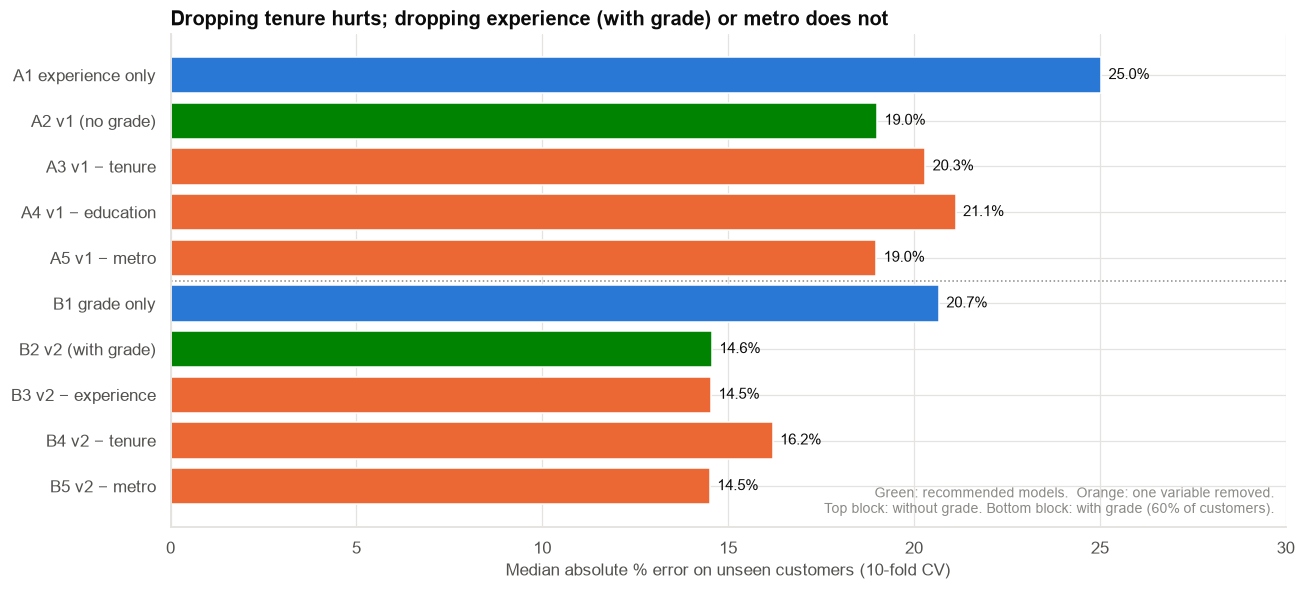

In [21]:
fig, ax = plt.subplots(figsize=(12, 5.5))
order = list(cv_tbl.index)[::-1]
cols = [COLORS["green"] if k in ("A2 v1 (no grade)", "B2 v2 (with grade)") else (HIGHLIGHT if "−" in k else PRIMARY) for k in order]
ax.barh(order, cv_tbl.loc[order, "median abs. % error"], color=cols)
for i, k in enumerate(order):
    ax.text(cv_tbl.loc[k, "median abs. % error"] + 0.2, i, f"{cv_tbl.loc[k, 'median abs. % error']:.1f}%", va="center", fontsize=10)
ax.axhline(4.5, color=INK_MUTED, lw=1, ls=":")
ax.set(xlabel="Median absolute % error on unseen customers (10-fold CV)", xlim=(0, 30),
       title="Dropping tenure hurts; dropping experience (with grade) or metro does not")
add_note(ax, "Green: recommended models.  Orange: one variable removed.\nTop block: without grade. Bottom block: with grade (60% of customers).", "lower right")
fig.tight_layout()
save_fig(fig, "fig09_prediction_comparison", PATHS["figures"])
plt.show()

In [22]:
def drop_test(full_f, var_term, label):
    m_full = smf.ols(full_f, cust).fit()
    m_red = smf.ols(full_f.replace(var_term, ""), cust).fit()
    a = anova_lm(m_red, m_full)
    return {"model": label, "F": a["F"].iloc[1], "df": int(a["df_diff"].iloc[1]), "p_value": a["Pr(>F)"].iloc[1],
            "partial R²": (m_red.ssr - m_full.ssr) / m_red.ssr}

v2f = nograde + " + grade"
tests = pd.DataFrame([
    drop_test(nograde, "years_experience + ", "v1: drop experience"),
    drop_test(nograde, " + years_at_current_employer", "v1: drop tenure"),
    drop_test(nograde, " + education", "v1: drop education"),
    drop_test(nograde, " + metro_city", "v1: drop metro"),
    drop_test(v2f, "years_experience + ", "v2: drop experience"),
    drop_test(v2f, " + years_at_current_employer", "v2: drop tenure"),
    drop_test(v2f, " + education", "v2: drop education"),
    drop_test(v2f, " + metro_city", "v2: drop metro"),
]).set_index("model")
save_table(tests, "nested_f_tests", PATHS["tables"])
tests

,F,df,p_value,partial R²
model,,,,
v1: drop experience,"2,521.2184",1,0.0000,0.2963
v1: drop tenure,892.0835,1,0.0000,0.1296
v1: drop education,421.8012,3,0.0000,0.1744
v1: drop metro,1.3678,1,0.2422,0.0002
v2: drop experience,38.4162,1,0.0000,0.0064
v2: drop tenure,"1,563.3291",1,0.0000,0.2071
v2: drop education,126.9208,3,0.0000,0.0598
v2: drop metro,2.2163,1,0.1366,0.0004


**Observation.**
- **Without grade (v1):** experience is essential (the largest partial R², ≈ 0.30). Tenure and education are also
  important: dropping either raises the median error from 19.0% to 20–21%. Metro adds nothing.
- **With grade (v2):** dropping experience changes the cross-validated error by **less than 0.1 percentage points**,
  even though its F-test is significant (p < 0.001): **statistically detectable, practically negligible** (Case 22).
  Dropping tenure still hurts clearly. Metro adds nothing.

**Interpretation.** For *prediction*, a variable matters if it adds information **that the other variables do not
already carry**. Once grade is known, grade already carries most of what experience says. For customers without a
verified grade (40%), experience is the main signal we have.

**Business implication.** Experience must stay on the application form: model v1 (for customers without grade) depends
on it. In v2 it can stay or go with no real cost; keeping it is simpler (one form, one variable list) and protects
against grade data being unavailable.

## Section 14 — How robust are these conclusions to an unmeasured confounder?

The obvious unmeasured variable is **individual ability or performance**: it could raise both promotions and pay.
The **robustness value** (RV, Cinelli & Hazlett 2020) answers: *how strongly would an unmeasured confounder have to be
associated with both the variable and salary (each as a share of remaining variance, partial R²) to remove the
estimated effect entirely, or to make it statistically insignificant?*

In [23]:
def robustness(m, term):
    t, dof = m.tvalues[term], m.df_resid
    f = abs(t) / np.sqrt(dof)
    rv = 0.5 * (np.sqrt(f ** 4 + 4 * f ** 2) - f ** 2)
    fa = f - stats.t.ppf(0.975, dof - 1) / np.sqrt(dof - 1)
    rv_a = 0.0 if fa <= 0 else 0.5 * (np.sqrt(fa ** 4 + 4 * fa ** 2) - fa ** 2)
    return {"estimate (%)": pct(m.params[term]), "t": t, "partial R² of term": t ** 2 / (t ** 2 + dof),
            "RV: confounder strength to remove effect": rv, "RV: … to make it insignificant (α=0.05)": rv_a}

rob = pd.DataFrame({
    "experience, total (v1)": robustness(m_v1, "years_experience"),
    "experience, direct (v2)": robustness(m_v2, "years_experience"),
    "tenure (v2)": robustness(m_v2, "years_at_current_employer"),
    "Postgraduate vs Graduate (v1)": robustness(m_v1, "education[T.Postgraduate]"),
    "metro (v2)": robustness(m_v2, "metro_city"),
}).T
save_table(rob, "robustness_values", PATHS["tables"])
rob

,estimate (%),t,partial R² of term,RV: confounder strength to remove effect,RV: … to make it insignificant (α=0.05)
"experience, total (v1)",4.2843,50.2117,0.2963,0.4716,0.4587
"experience, direct (v2)",0.5286,6.1981,0.0064,0.0770,0.0533
tenure (v2),-3.9732,-39.5390,0.2071,0.3969,0.3819
Postgraduate vs Graduate (v1),20.7523,18.7084,0.0552,0.2143,0.1943
metro (v2),-0.9348,-1.4887,0.0004,0.0191,0.0000


**How to read the robustness value.** An RV of 0.47 for experience's total effect means: an unmeasured confounder
would need to explain **at least 47%** of the remaining variation in *both* experience and salary to wipe the effect
out. That is far stronger than any variable we observe, so the conclusion is robust.

**Observation.**
- **Experience (total), tenure, postgraduate premium:** RVs of roughly 0.2–0.47. Very robust.
- **Experience (direct, at the same grade):** RV ≈ 0.08 to remove it, about 0.05 to make it insignificant. A
  moderately strong unmeasured factor (say, a performance rating that also predicts years in work) could explain the
  small direct effect away. **Do not build a story on the +0.5%.**
- **Metro:** RV to make it insignificant is 0: it is already insignificant.

**Rule of thumb.** Compare the RV with the partial R² of your **strongest observed** controls. If a hidden variable
would need to be several times stronger than anything you measured, the conclusion is robust.

## Section 15 — Diagnostics

VIF in model v2 (largest first):
years_experience            4.5800
grade_3                     2.5300
grade_4                     2.2300
years_at_current_employer   2.1800
grade_2                     1.7600
education_Postgraduate      1.5500

If age were added as well: VIF(age) = 28, VIF(experience) = 35


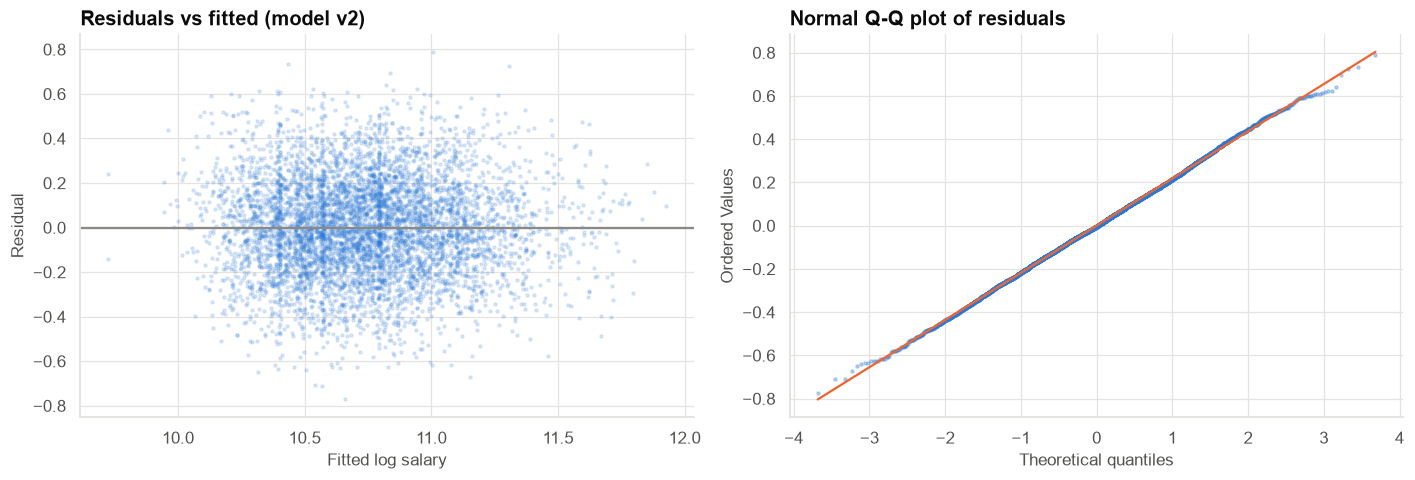

In [24]:
X = pd.get_dummies(cust[["years_experience", "years_at_current_employer", "metro_city", "education", "employer_category", "grade"]],
                   drop_first=True, dtype=float).assign(const=1.0)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns).drop("const")
X_age = X.assign(age=cust["age"])
vif_age = variance_inflation_factor(X_age.values, list(X_age.columns).index("age"))
vif_exp_age = variance_inflation_factor(X_age.values, list(X_age.columns).index("years_experience"))
print("VIF in model v2 (largest first):")
print(vif.sort_values(ascending=False).head(6).round(2).to_string())
print(f"\nIf age were added as well: VIF(age) = {vif_age:.0f}, VIF(experience) = {vif_exp_age:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(m_v2.fittedvalues, m_v2.resid, s=4, alpha=0.15, color=PRIMARY)
axes[0].axhline(0, color=INK_MUTED)
axes[0].set(xlabel="Fitted log salary", ylabel="Residual", title="Residuals vs fitted (model v2)")
stats.probplot(m_v2.resid, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(markersize=2, alpha=0.3, color=PRIMARY)
axes[1].get_lines()[1].set(color=HIGHLIGHT)
axes[1].set_title("Normal Q-Q plot of residuals")
fig.tight_layout()
save_fig(fig, "fig10_diagnostics", PATHS["figures"])
plt.show()

**Observation.** VIFs in v2 are moderate (experience and the grade dummies are correlated, as expected for a variable
and its mediator), with no sign of the extreme values that would make estimates unstable. Adding **age** would push
the VIFs of age and experience to about 30: the two are almost the same variable. Residuals are centred, have
even spread, and look close to normal.

**Interpretation.** Moderate correlation between experience and grade is not a defect to "fix": it is the mediation
we are studying. It only widens the CI of experience's direct effect, which is still narrow at n = 6,000.

## Section 16 — Results

In [25]:
summary = pd.DataFrame([
    ["Experience", "+1.5%/yr", "+4.3%/yr (v1) → +0.5%/yr (v2)", "Mediation: ~87% runs through job grade",
     "Keep (essential when grade is missing)"],
    ["Metro city", "+12%", "≈ −1% (CI includes 0)", "Confounding by employer type", "Reject the metro uplift"],
    ["Years at current employer", "≈ 0 (r ≈ 0.0)", "−3.9%/yr", "Suppression by experience", "Keep (2nd most useful in v2)"],
    ["Postgraduate vs Graduate", "≈ 0", "+21% (same experience); +9% (same grade)", "Masked by experience (young postgraduates)",
     "Keep education"],
], columns=["Variable", "On its own", "Conditional", "What happened", "Decision"]).set_index("Variable")
save_table(summary, "results_summary", PATHS["tables"])
summary

,On its own,Conditional,What happened,Decision
Variable,,,,
Experience,+1.5%/yr,+4.3%/yr (v1) → +0.5%/yr (v2),Mediation: ~87% runs through job grade,Keep (essential when grade is missing)
Metro city,+12%,≈ −1% (CI includes 0),Confounding by employer type,Reject the metro uplift
Years at current employer,≈ 0 (r ≈ 0.0),−3.9%/yr,Suppression by experience,Keep (2nd most useful in v2)
Postgraduate vs Graduate,≈ 0,+21% (same experience); +9% (same grade),Masked by experience (young postgraduates),Keep education


## Section 17 — Interpretation

The four dashboard claims were wrong in four different ways:

| Pattern | What we saw | Mechanism | Correct action |
|---|---|---|---|
| Coefficient **shrinks** when Z is added; Z **comes after** X | Experience, after adding grade | **Mediation** | For total effect: do **not** adjust for Z. For prediction: use Z if available |
| Coefficient **shrinks to ≈ 0**; Z **comes before** X and causes Y | Metro, after adding employer type | **Confounding** | Adjust for Z; the raw association was spurious |
| **≈ 0 alone**, clear effect conditionally; two paths of opposite sign | Tenure, given experience | **Suppression** | Keep it; judge it conditionally |
| **Hidden** alone; appears when a negatively correlated driver is added | Education, given experience | **Masking** (a confounder in *this* sample) | Keep it; the sample composition hid it |
| Coefficient **unchanged**, SE **smaller** | Experience, after adding employer type | Z predicts Y, unrelated to X: a **precision** variable | Add it: free precision |
| Coefficients **attenuated** in a sub-sample | Premium segment only | **Selection on the outcome** | Never filter on Y |

**The diagnostic checklist when a coefficient changes after adding Z**

1. Does Z relate to **both** X and Y? (If not, the coefficient should not move much. Check with the γ·δ formula.)
2. Which came first, X or Z? **Before X → confounder** (adjust). **After X, because of X → mediator** (depends on the
   question). **Caused by both X and Y → collider / bad control** (never adjust; Case 07's tenure example).
3. Is the goal **prediction** or **explanation**? For prediction, any variable available at prediction time that adds
   out-of-sample accuracy is fair game (except leakage, Case 13). For explanation, the causal diagram decides.
4. How robust is the conclusion to what we did not measure? (Robustness value.)

## Section 18 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "Customers with more experience earn more, by about 4% per year at the same education, employer and tenure; most of this runs through promotions." | "Experience doesn't matter." |
| "At the same grade, experience adds about 0.5% per year, but this small effect is sensitive to unmeasured factors." | "Each extra year of experience **causes** a 4% raise." (Observational data; ability could matter.) |
| "The metro premium disappears once employer type is accounted for." | "Moving to a metro does not change pay." (We did not study movers.) |
| "At the same experience, customers who have stayed longer with one employer earn less." | "Staying with one employer **causes** lower pay." (Plausible, but not proven by this design.) |
| "At the same experience, postgraduates in our customer base earn about 20% more than graduates." | "A postgraduate degree raises salary by 20%." (Selection into degrees is not random.) |

## Section 19 — Business interpretation

For the income estimator, which is a **prediction** tool, the questions are practical: does the variable add accuracy,
is it available, and does it double-count?
- **Experience:** keep. It is the main signal for the 40% of customers without a verified grade. In v2 it adds little
  but costs nothing.
- **Metro uplift:** reject. It double-counts the employer effect.
- **Tenure:** keep. Dropping it would make estimates materially worse.
- **Education:** keep. Its premium is large; the raw comparison was distorted by sample composition.

## Section 20 — Limitations

- **Observational data.** Total/direct splits and "effects" are associations within a linear model. Ability and
  performance are unmeasured.
- **Customer base, not the labour market.** The education masking is specific to our sample (campus partnership).
- **Grade as a categorical variable** assumes each grade has its own pay level and the same experience slope; small top
  grades give noisy within-grade slopes.
- **Synthetic data** with a known data-generating process (`src/generate_data.py`).

## Section 21 — Final recommendation

> **Approve model v2 for customers with a verified grade and keep model v1 for the rest. Keep experience on the
> application form, keep tenure and education in both models, and reject the metro uplift.** Experience did not stop
> mattering; its effect is now carried by job grade, which is how promotions turn experience into pay.

## Section 22 — What would I do next?

1. **Monitor** the share of customers with verified grade; if it grows, re-check v1's calibration on the shrinking
   group without grade.
2. **Validate v1 and v2 on the next quarter** (out-of-time), including errors by employer type and education.
3. Look for a **performance or bureau-based proxy for ability** to reduce the main unmeasured-confounder risk.
4. Use the diagnostic checklist (Section 17) as a **standard step** in model reviews: every time a coefficient changes
   sign or size between versions, classify it before anyone acts on it.
5. Continue to **Case 09** (multicollinearity: when two good variables are too similar to separate) and **Case 20**
   (Simpson's paradox, the categorical version of this case).